# The Rust fast paths inside meK-Means

Four steps of the meK-Means EM loop in `mminference.py` have Rust implementations in
`monod_core`, used automatically when the extension is installed (the k-means
initialization also needs the extension built with the `kmeans` feature):

| Rust function | Replaces | What it accelerates |
|---|---|---|
| `e_step_2d` | Python loop in `_e_step` | PSS evaluation over clusters × genes in parallel (rayon), softmax in Rust |
| `optimize_genes_2d_sd` | scipy L-BFGS-B loop in `iterate_over_genes` | L-BFGS-B over all genes in parallel, straight from the Rust `SearchData` |
| `partition_searchdata_2d` | NumPy loop in `_part_search_data` | Cell filtering and histogram/moment rebuild per cluster |
| `initialize_q_kmeans` | sklearn `KMeans` in `_initialize_Q` | log1p-normalised k-means via linfa |

This notebook checks each one against its Python fallback and times it on PBMC 10k
(10 997 cells, 100 genes), then runs the two-stage procedure that meK-Means uses with a
technical-noise model.  The end-to-end run and the comparison with the annotated cell
types are in `mek_means.ipynb`.  Needs `example_h5ad/processed_pbmc_10k_raw.h5ad` and
the extension; takes about a minute.


## Setup


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import os, time, logging, warnings
import numpy as np
import scipy.optimize
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import adjusted_rand_score
import anndata as ad

from monod._core import _mc                       # the compiled extension, None if absent
from monod.cme_toolbox import CMEModel
from monod.extract_data import extract_data, select_expressed_genes
from monod.inference import InferenceParameters, searchdata_from_adata
import monod.mminference as mm
from monod.mminference import MEKMeansParameters, GradientInference, cell_assignments
from monod.analysis import plot_cluster_confusion, match_clusters

if _mc is None:
    raise ImportError('monod_core is not installed: pip install monod-core, '
                      'or build it with  cd monod_core && maturin develop --release')
os.makedirs('figures', exist_ok=True)
warnings.filterwarnings('ignore')
# The fits here use few L-BFGS-B iterations on purpose, which leaves some genes short
# of convergence; silence the per-epoch log and those notes.
logging.disable(logging.WARNING)
C_PY, C_RUST = 'steelblue', 'firebrick'

print(f'monod_core              : {_mc.__file__}')
print(f'mminference._HAS_RUST   : {mm._HAS_RUST}')
print(f'mminference._HAS_KMEANS : {mm._HAS_KMEANS}  (needs the kmeans feature)')


monod_core              : /home/coakes/miniconda3/envs/monod/lib/python3.11/site-packages/monod_core/__init__.py
mminference._HAS_RUST   : True
mminference._HAS_KMEANS : True  (needs the kmeans feature)


In [3]:
# ── Load PBMC 10k dataset ────────────────────────────────────────────────────
adata = ad.read_h5ad('example_h5ad/processed_pbmc_10k_raw.h5ad')
adata.var_names_make_unique()

cell_types = adata.obs['subclass_label'].values
unique_types, type_counts = np.unique(cell_types, return_counts=True)
print(f'Dataset: {adata.n_obs:,} cells  |  {adata.n_vars:,} genes')
print('Cell types:')
for ct, n in sorted(zip(unique_types, type_counts), key=lambda x: -x[1]):
    print(f'  {ct:20s}: {n:5,} cells ({100*n/adata.n_obs:.1f}%)')

var_to_name = dict(zip(adata.var_names, adata.var['gene_name']))

Dataset: 10,997 cells  |  36,601 genes
Cell types:
  Tcells              : 5,375 cells (48.9%)
  Monocytes           : 3,972 cells (36.1%)
  Bcells              : 1,650 cells (15.0%)


In [4]:
# ── Select expressed genes and build the search data ─────────────────────────
MODEL   = CMEModel('Bursty', 'None')
N_GENES = 100
K       = 3          # the three annotated cell types

# The first 100 genes (file order) seen in at least 100 cells, counted on the sparse matrix.
GENES = select_expressed_genes(adata, min_cells=100, n_genes=N_GENES)
gene_display = [var_to_name[g] for g in GENES]

t0 = time.perf_counter()
adata_ext = extract_data(
    adata, MODEL,
    dataset_name='pbmc_mek_means_rust',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=N_GENES, genes_to_fit=GENES,
    hist_type='unique', viz=False,
)
search_data = searchdata_from_adata(adata_ext)
n_cells = search_data.n_cells
print(f'SearchData ready in {time.perf_counter()-t0:.1f}s: '
      f'{search_data.n_genes} genes, {n_cells:,} cells  '
      f'(Rust SearchData: {isinstance(search_data, _mc.SearchData)})')


GRAD = {'max_iterations': 15, 'init_pattern': 'moments', 'num_restarts': 1}

def make_gi(sd, k=K, epochs=1, rust_optimizer=True):
    """A meK-Means GradientInference for sd through the public constructors (nothing is
    written to disk).  rust_optimizer=False selects scipy L-BFGS-B for the M-step."""
    mp = MEKMeansParameters('pbmc_mek_means_rust', MODEL, use_lengths=False,
                            gradient_params={**GRAD, 'use_rust_lbfgsb': rust_optimizer},
                            k=k, epochs=epochs, random_state=0)
    return GradientInference(mp, MODEL, sd, 0, k, epochs)


def time_call(fn, reps, rust_on=True):
    """Median wall time (ms) of fn() over reps calls, with the meK-Means Rust paths
    switched on or off for the duration."""
    was = mm._HAS_RUST
    mm._HAS_RUST = rust_on
    try:
        ts = []
        for _ in range(reps):
            t0 = time.perf_counter()
            fn()
            ts.append((time.perf_counter() - t0) * 1e3)
    finally:
        mm._HAS_RUST = was
    return float(np.median(ts))


SearchData ready in 3.0s: 100 genes, 10,997 cells  (Rust SearchData: True)


---
## 1  E-step fast path: `e_step_2d`

For each cell $c$ and cluster $k$ the E-step computes
$$\log L_{c,k} = \sum_g \log P_{\theta_k^g}(u_c^g, s_c^g) + \log w_k$$
and the posterior $Q_{c,k} = \mathrm{softmax}_k(\log L_{c,\cdot})$.

`e_step_2d` evaluates all $k \times G$ distributions in parallel (rayon) and runs the
softmax inside Rust, in one call that releases the GIL.  The fallback is the loop in
`_e_step`: one `eval_model_pss` call per cluster and gene (each call itself uses the
Rust PSS kernel when the extension is present), then the softmax in NumPy.  Both are
called through `_e_step` here, toggling `mminference._HAS_RUST`.  Both spend most of their time in the same
PSS kernel, so the gain is the per-call overhead of the Python loop over clusters and genes.


In [5]:
# ── One M-step, to have fitted parameters for every cluster ──────────────────
gi = make_gi(search_data)
Q_init = gi._initialize_Q(search_data)
k_dict = gi._part_search_data(search_data, Q_init)
gi._m_step(MODEL, k_dict, Q_init)
print(f'Initial M-step done.  Clusters with data: {sorted(gi.theta)}')
print(f'Parameters per cluster: {gi.theta[0][0].shape}  (genes × parameters)')


Initial M-step done.  Clusters with data: [0, 1, 2]
Parameters per cluster: (100, 3)  (genes × parameters)


In [6]:
# ── Correctness: Rust vs Python E-step ───────────────────────────────────────
gi._e_step(MODEL, search_data)                 # warms up the rayon thread pool
t0 = time.perf_counter()
Q_rust, lb_rust, _ = gi._e_step(MODEL, search_data)
t_rust_e = time.perf_counter() - t0

mm._HAS_RUST = False
try:
    t0 = time.perf_counter()
    Q_py, lb_py, _ = gi._e_step(MODEL, search_data)
    t_py_e = time.perf_counter() - t0
finally:
    mm._HAS_RUST = True

max_diff = np.abs(Q_rust - Q_py).max()
print(f'Max |Q_rust − Q_python| = {max_diff:.2e}   lower bound {lb_rust:.6f} vs {lb_py:.6f}')
print(f'E-step  Rust={t_rust_e*1e3:.0f} ms  Python={t_py_e*1e3:.0f} ms  ({t_py_e/t_rust_e:.1f}×)')
assert max_diff < 1e-8


Max |Q_rust − Q_python| = 3.66e-15   lower bound -101.628518 vs -101.628518
E-step  Rust=112 ms  Python=145 ms  (1.3×)


In [7]:
# ── Benchmark: E-step wall time vs number of genes ───────────────────────────
GENE_COUNTS = [5, 10, 25, 50, 75, 100]
N_REPS = 10
rust_e_times, py_e_times = [], []

for ng in GENE_COUNTS:
    sd_n = searchdata_from_adata(adata_ext[:, GENES[:ng]].copy())   # subsets keep their grid limits
    gi_n = make_gi(sd_n)
    gi_n.theta   = {k: (gi.theta[k][0][:ng],) + tuple(gi.theta[k][1:]) for k in gi.theta}
    gi_n.weights = gi.weights
    rust_e_times.append(time_call(lambda: gi_n._e_step(MODEL, sd_n), N_REPS, rust_on=True))
    py_e_times.append(time_call(lambda: gi_n._e_step(MODEL, sd_n), N_REPS, rust_on=False))
    print(f'  n_genes={ng:3d}  Python={py_e_times[-1]:6.0f} ms  Rust={rust_e_times[-1]:5.0f} ms'
          f'  ({py_e_times[-1]/rust_e_times[-1]:.1f}×)')


  n_genes=  5  Python=     6 ms  Rust=   13 ms  (0.5×)


  n_genes= 10  Python=    11 ms  Rust=   27 ms  (0.4×)


  n_genes= 25  Python=    44 ms  Rust=   48 ms  (0.9×)


  n_genes= 50  Python=    60 ms  Rust=   73 ms  (0.8×)


  n_genes= 75  Python=   102 ms  Rust=  106 ms  (1.0×)


  n_genes=100  Python=   138 ms  Rust=  120 ms  (1.2×)


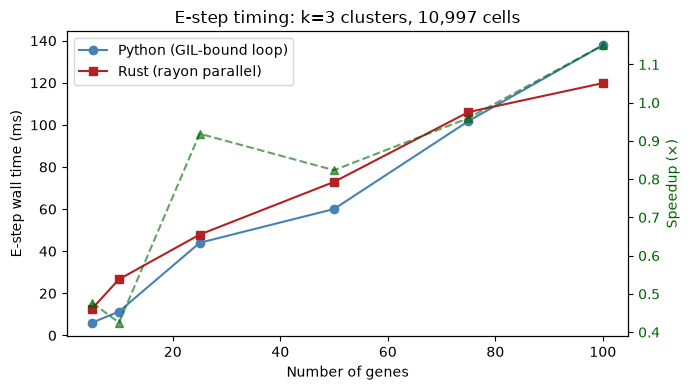

Peak E-step speedup: 1.2× at 100 genes


In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(GENE_COUNTS, py_e_times,   'o-', color=C_PY,   label='Python (GIL-bound loop)')
ax.plot(GENE_COUNTS, rust_e_times, 's-', color=C_RUST,  label='Rust (rayon parallel)')
ax.set_xlabel('Number of genes')
ax.set_ylabel('E-step wall time (ms)')
ax.set_title(f'E-step timing: k={K} clusters, {n_cells:,} cells')
ax.legend()
ax2 = ax.twinx()
speedups_e = [p/r for p, r in zip(py_e_times, rust_e_times)]
ax2.plot(GENE_COUNTS, speedups_e, '^--', color='darkgreen', alpha=0.6)
ax2.set_ylabel('Speedup (×)', color='darkgreen')
ax2.tick_params(axis='y', labelcolor='darkgreen')
fig.tight_layout()
plt.savefig('figures/pbmc_estep_bench.png', dpi=150)
plt.show()
print(f'Peak E-step speedup: {max(speedups_e):.1f}× at {GENE_COUNTS[np.argmax(speedups_e)]} genes')

---
## 2  M-step fast path: `optimize_genes_2d_sd`

`iterate_over_genes` is shared with `inference.py`.  With a Rust `SearchData` and
`gradient_params['use_rust_lbfgsb']` on (the `MEKMeansParameters` default when the
extension is present) the whole M-step runs in the Rust L-BFGS-B kernel, all genes in
parallel under rayon.  `use_rust_lbfgsb=False` runs scipy's L-BFGS-B gene by gene,
each KLD evaluation still in the Rust kernel.  `mminference._HAS_RUST` does not select
the optimizer; a full Python-fallback EM still ends up in scipy because the fallback
partition (section 3) returns Python `SearchData` objects.


In [9]:
# ── Correctness: Rust L-BFGS-B vs scipy on one cluster ───────────────────────
first_k = sorted(k_dict)[0]
sd_k = k_dict[first_k]
print(f'Cluster {first_k}: {sd_k.n_cells:,} cells, {sd_k.n_genes} genes')

gi_r = make_gi(sd_k)                          # same moment-based starting points
gi_s = make_gi(sd_k, rust_optimizer=False)
t0 = time.perf_counter()
params_rust, klds_rust, obj_rust, _ = gi_r.iterate_over_genes(MODEL, sd_k)
t_rust_m = time.perf_counter() - t0
t0 = time.perf_counter()
params_scipy, klds_scipy, obj_scipy, _ = gi_s.iterate_over_genes(MODEL, sd_k)
t_py_m = time.perf_counter() - t0

ratio = np.asarray(klds_rust) / np.clip(np.asarray(klds_scipy), 1e-15, None)
print(f'KLD ratio Rust/scipy  min={ratio.min():.3f}  median={np.median(ratio):.3f}  max={ratio.max():.3f}')
print(f'Total KLD  Rust={obj_rust:.4f}  scipy={obj_scipy:.4f}')
print(f'Max |Δ log10 parameter| = {np.abs(np.asarray(params_rust) - np.asarray(params_scipy)).max():.3f}')
print(f'Wall time  Rust={t_rust_m*1e3:.0f} ms  scipy={t_py_m*1e3:.0f} ms  ({t_py_m/t_rust_m:.1f}×)')


Cluster 0: 3,118 cells, 100 genes


KLD ratio Rust/scipy  min=0.956  median=1.000  max=1.000
Total KLD  Rust=1.1839  scipy=1.1839
Max |Δ log10 parameter| = 0.115
Wall time  Rust=88 ms  scipy=392 ms  (4.5×)


### 2b  Optimizer comparison: Rust L-BFGS-B (analytic ∇) vs scipy L-BFGS-B (analytic ∇)

Both optimizers receive the same starting point and the same analytic gradient —
the only difference is the L-BFGS-B *implementation* (Rust `lbfgsb_rs_pure` vs scipy's
Fortran wrapper).  Tolerances are matched: `ftol=1e-10`, `gtol=1e-6`, `maxiter=200`.

We track the parameter trajectory and KLD at every step to see where (if anywhere)
the two paths diverge.

Rust  converged: True  steps=9  final KLD=0.000353  params=[1.00000000e-01 3.16227766e+02 6.27345268e+00]
scipy converged: True  steps=9  final KLD=0.000353  params=[1.00000000e-01 3.16227766e+02 6.27345268e+00]
Final KLD diff: 0.00e+00
Final param diff (log10): [0. 0. 0.]


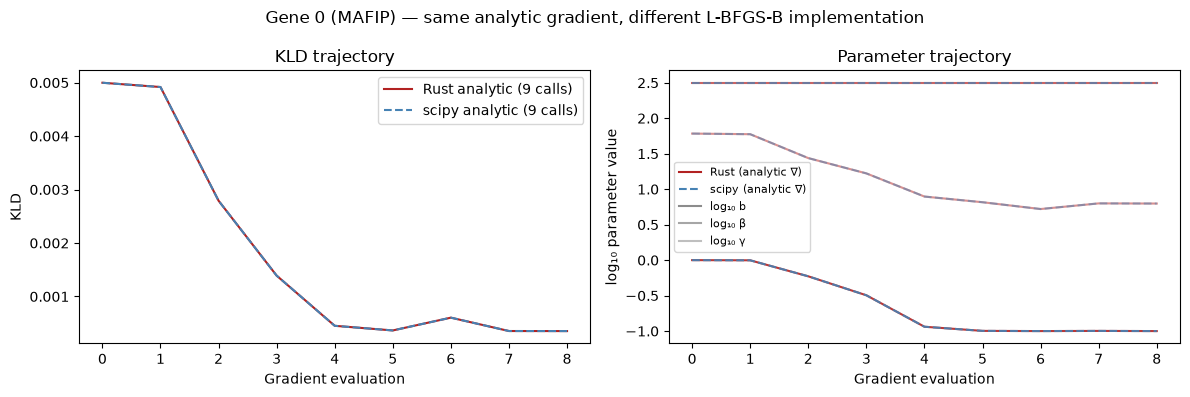

In [10]:
# ── Optimizer comparison: same analytic gradient, different L-BFGS-B impl ────
# One gene from the first cluster's search data (section 2).
sd_cmp   = sd_k
GENE_IDX = 0

# Starting point: MoM estimate for this gene.
lb  = gi.phys_lb
ub  = gi.phys_ub
x0  = gi.param_MoM[GENE_IDX].copy()
x0  = np.clip(x0, lb, ub)

# Shared optimizer settings.
FTOL    = 1e-10
GTOL    = 1e-6
MAXITER = 200

# ── 1. Rust L-BFGS-B (analytic gradient) ─────────────────────────────────────
# The Rust callback (eval_kld_grad_2d) takes the analytic-gradient path for
# Bursty, the one optimize_genes_2d_sd uses inside the M-step.
hist_g   = sd_cmp.hist[GENE_IDX]
M_g      = sd_cmp.M[:, GENE_IDX].tolist()
coords_g = np.asarray(hist_g[0], dtype=np.int64)
freqs_g  = np.asarray(hist_g[1], dtype=float)
samp_g   = None

rust_traj_kld    = []
rust_traj_params = []

# Use eval_kld_grad_2d to replicate what lbfgsb_minimize does, step by step,
# by running scipy with jac=True and the Rust analytic gradient function.
# This gives us full trajectory visibility that lbfgsb_minimize doesn't expose.
def rust_obj_and_grad(p):
    kld, grad = _mc.eval_kld_grad_2d(
        MODEL.bio_model, p.tolist(), [int(v) for v in M_g],
        coords_g[:, 0].tolist(), coords_g[:, 1].tolist(),
        freqs_g.tolist(),
        float(MODEL.fixed_quad_T), MODEL.quad_order,
        1e-8, samp_g, 1e-15, MODEL.seq_model,
    )
    rust_traj_kld.append(kld)
    rust_traj_params.append(p.copy())
    return kld, np.array(grad)

res_rust = scipy.optimize.minimize(
    rust_obj_and_grad, x0, method='L-BFGS-B', jac=True,
    bounds=scipy.optimize.Bounds(lb, ub),
    options={'maxiter': MAXITER, 'ftol': FTOL, 'gtol': GTOL, 'disp': False},
)

# ── 2. scipy L-BFGS-B (analytic gradient, Python path) ───────────────────────
scipy_traj_kld    = []
scipy_traj_params = []

data_g = (coords_g, freqs_g)

def scipy_obj_and_grad(p):
    kld, grad = MODEL.eval_model_kld_and_grad(
        p, M_g, samp_g, data_g,
    )
    scipy_traj_kld.append(kld)
    scipy_traj_params.append(p.copy())
    return kld, np.array(grad)

res_scipy = scipy.optimize.minimize(
    scipy_obj_and_grad, x0, method='L-BFGS-B', jac=True,
    bounds=scipy.optimize.Bounds(lb, ub),
    options={'maxiter': MAXITER, 'ftol': FTOL, 'gtol': GTOL, 'disp': False},
)

rust_traj_kld    = np.array(rust_traj_kld)
scipy_traj_kld   = np.array(scipy_traj_kld)
rust_traj_params = np.array(rust_traj_params)
scipy_traj_params= np.array(scipy_traj_params)

print(f'Rust  converged: {res_rust.success}  steps={len(rust_traj_kld)}  '
      f'final KLD={res_rust.fun:.6f}  params={10**res_rust.x}')
print(f'scipy converged: {res_scipy.success}  steps={len(scipy_traj_kld)}  '
      f'final KLD={res_scipy.fun:.6f}  params={10**res_scipy.x}')
print(f'Final KLD diff: {abs(res_rust.fun - res_scipy.fun):.2e}')
print(f'Final param diff (log10): {np.abs(res_rust.x - res_scipy.x)}')

# ── Plot trajectories ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(rust_traj_kld,  color=C_RUST, lw=1.5, label=f'Rust analytic ({len(rust_traj_kld)} calls)')
ax.plot(scipy_traj_kld, color=C_PY,   lw=1.5, label=f'scipy analytic ({len(scipy_traj_kld)} calls)', ls='--')
ax.set_xlabel('Gradient evaluation')
ax.set_ylabel('KLD')
ax.set_title('KLD trajectory')
ax.legend()

param_names = ['log₁₀ b', 'log₁₀ β', 'log₁₀ γ']
ax = axes[1]
for i, name in enumerate(param_names):
    ax.plot(rust_traj_params[:, i],  color=C_RUST, lw=1.5,
            label=f'Rust {name}' if i == 0 else '_', alpha=0.9 - i*0.2)
    ax.plot(scipy_traj_params[:, i], color=C_PY,   lw=1.5,
            label=f'scipy {name}' if i == 0 else '_', ls='--', alpha=0.9 - i*0.2)
ax.set_xlabel('Gradient evaluation')
ax.set_ylabel('log₁₀ parameter value')
ax.set_title('Parameter trajectory')
# Manual legend for rust vs scipy
ax.legend(handles=[
    Line2D([0],[0], color=C_RUST, lw=1.5, label='Rust (analytic ∇)'),
    Line2D([0],[0], color=C_PY,   lw=1.5, ls='--', label='scipy (analytic ∇)'),
] + [Line2D([0],[0], color='grey', lw=1.5, alpha=0.9-i*0.2,
            label=name) for i, name in enumerate(param_names)], fontsize=8)

fig.suptitle(f'Gene {GENE_IDX} ({gene_display[GENE_IDX]}) — same analytic gradient, '
             f'different L-BFGS-B implementation')
fig.tight_layout()
fig.savefig('figures/optimizer_comparison.png', dpi=150)
plt.show()

In [11]:
# ── Benchmark: M-step wall time vs number of genes (whole population) ────────
GENE_COUNTS_M = [5, 10, 25, 50, 100]
rust_m_times, py_m_times = [], []

for ng in GENE_COUNTS_M:
    sd_n = searchdata_from_adata(adata_ext[:, GENES[:ng]].copy())   # subsets keep their grid limits
    gi_rn, gi_sn = make_gi(sd_n), make_gi(sd_n, rust_optimizer=False)
    t0 = time.perf_counter()
    gi_rn.iterate_over_genes(MODEL, sd_n)
    rust_m_times.append((time.perf_counter() - t0) * 1e3)
    t0 = time.perf_counter()
    gi_sn.iterate_over_genes(MODEL, sd_n)
    py_m_times.append((time.perf_counter() - t0) * 1e3)
    print(f'  n_genes={ng:3d}  scipy={py_m_times[-1]:7.0f} ms  Rust={rust_m_times[-1]:5.0f} ms'
          f'  ({py_m_times[-1]/rust_m_times[-1]:.1f}×)')


  n_genes=  5  scipy=     16 ms  Rust=    4 ms  (4.3×)
  n_genes= 10  scipy=     28 ms  Rust=    8 ms  (3.4×)


  n_genes= 25  scipy=    132 ms  Rust=   32 ms  (4.2×)


  n_genes= 50  scipy=    262 ms  Rust=   64 ms  (4.1×)


  n_genes=100  scipy=    524 ms  Rust=   75 ms  (7.0×)


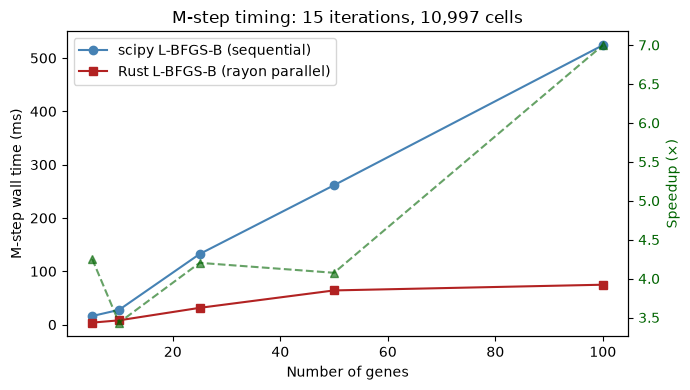

Peak M-step speedup: 7.0× at 100 genes


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(GENE_COUNTS_M, py_m_times,   'o-', color=C_PY,   label='scipy L-BFGS-B (sequential)')
ax.plot(GENE_COUNTS_M, rust_m_times, 's-', color=C_RUST,  label='Rust L-BFGS-B (rayon parallel)')
ax.set_xlabel('Number of genes')
ax.set_ylabel('M-step wall time (ms)')
ax.set_title(f'M-step timing: {GRAD["max_iterations"]} iterations, {n_cells:,} cells')
ax.legend()
speedups_m = [p/r for p, r in zip(py_m_times, rust_m_times)]
ax2 = ax.twinx()
ax2.plot(GENE_COUNTS_M, speedups_m, '^--', color='darkgreen', alpha=0.6)
ax2.set_ylabel('Speedup (×)', color='darkgreen')
ax2.tick_params(axis='y', labelcolor='darkgreen')
fig.tight_layout()
plt.savefig('figures/pbmc_mstep_bench.png', dpi=150)
plt.show()
print(f'Peak M-step speedup: {max(speedups_m):.1f}× at {GENE_COUNTS_M[np.argmax(speedups_m)]} genes')

---
## 3  Cell partitioning: `partition_searchdata_2d`

After each E-step, cells are hard-assigned to their maximum-posterior cluster.
`_part_search_data` then rebuilds M (max + padding), histograms, and moments
for each cluster's cell subset.

`partition_searchdata_2d` does this entirely in Rust using rayon:
- Cell filtering per cluster is run in parallel across all clusters
- Per-gene histograms use the same `build_gene_histogram` helper as `make_state_dist`
- Moments (`compute_moments_inner`) are recomputed for the filtered cells

Activates automatically whenever `search_data` is a Rust `SearchData` object.

In [13]:
# ── Correctness: Rust partition vs Python fallback ───────────────────────────
Q_part = gi._initialize_Q(search_data)

t0 = time.perf_counter()
k_dict_rust = gi._part_search_data(search_data, Q_part)
t_rust_p = time.perf_counter() - t0

mm._HAS_RUST = False
try:
    t0 = time.perf_counter()
    k_dict_py = gi._part_search_data(search_data, Q_part)
    t_py_p = time.perf_counter() - t0
finally:
    mm._HAS_RUST = True

print(f'{"Cluster":>9}  {"n_cells (Rust)":>14}  {"n_cells (Python)":>16}  {"M match":>7}')
for k in sorted(k_dict_rust):
    r, p = k_dict_rust[k], k_dict_py[k]
    M_match = np.array_equal(np.asarray(r.M), np.asarray(p.M))
    print(f'{k:>9d}  {r.n_cells:>14,}  {p.n_cells:>16,}  {str(M_match):>7}')
print(f'\nPartition  Rust={t_rust_p*1e3:.1f} ms  Python={t_py_p*1e3:.1f} ms  ({t_py_p/t_rust_p:.1f}×)')
print(f'Returned objects: Rust {type(k_dict_rust[k]).__name__}, Python {type(k_dict_py[k]).__name__}')


  Cluster  n_cells (Rust)  n_cells (Python)  M match
        0           2,125             2,125     True
        1           5,462             5,462     True
        2           3,410             3,410     True

Partition  Rust=51.0 ms  Python=644.1 ms  (12.6×)
Returned objects: Rust SearchData, Python SearchData


  k=2  Python=    655 ms  Rust=   26 ms  (25.3×)


  k=3  Python=    614 ms  Rust=   28 ms  (21.9×)


  k=4  Python=    616 ms  Rust=   25 ms  (24.6×)


  k=6  Python=    604 ms  Rust=   23 ms  (25.8×)


  k=8  Python=    629 ms  Rust=   20 ms  (31.0×)


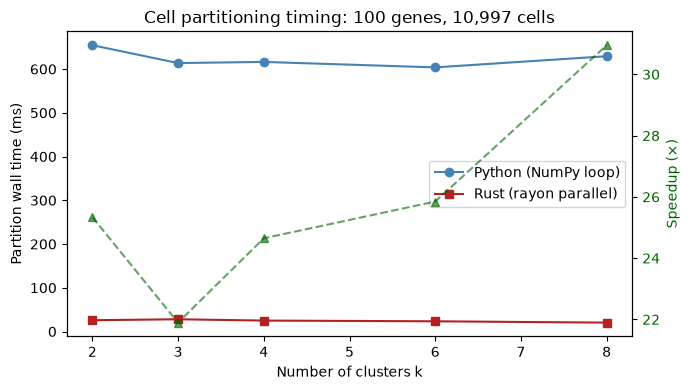

Peak partition speedup: 31.0× at k=8


In [14]:
# ── Benchmark: partition wall time vs number of clusters k ───────────────────
K_VALUES = [2, 3, 4, 6, 8]
N_REPS_P = 10
rust_p_times, py_p_times = [], []
rng = np.random.default_rng(0)

for kv in K_VALUES:
    Q_kv = rng.dirichlet(np.ones(kv), size=n_cells)
    gi_kv = make_gi(search_data, k=kv)
    rust_p_times.append(time_call(lambda: gi_kv._part_search_data(search_data, Q_kv), N_REPS_P, rust_on=True))
    py_p_times.append(time_call(lambda: gi_kv._part_search_data(search_data, Q_kv), N_REPS_P, rust_on=False))
    print(f'  k={kv}  Python={py_p_times[-1]:7.0f} ms  Rust={rust_p_times[-1]:5.0f} ms'
          f'  ({py_p_times[-1]/rust_p_times[-1]:.1f}×)')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(K_VALUES, py_p_times,   'o-', color=C_PY,   label='Python (NumPy loop)')
ax.plot(K_VALUES, rust_p_times, 's-', color=C_RUST, label='Rust (rayon parallel)')
ax.set_xlabel('Number of clusters k')
ax.set_ylabel('Partition wall time (ms)')
ax.set_title(f'Cell partitioning timing: {N_GENES} genes, {n_cells:,} cells')
ax.legend()
ax2 = ax.twinx()
speedups_p = [p/r for p, r in zip(py_p_times, rust_p_times)]
ax2.plot(K_VALUES, speedups_p, '^--', color='darkgreen', alpha=0.6)
ax2.set_ylabel('Speedup (×)', color='darkgreen')
ax2.tick_params(axis='y', labelcolor='darkgreen')
fig.tight_layout()
plt.savefig('figures/pbmc_partition_bench.png', dpi=150)
plt.show()
print(f'Peak partition speedup: {max(speedups_p):.1f}× at k={K_VALUES[np.argmax(speedups_p)]}')


---
## 4  Q initialization: `initialize_q_kmeans`

`_initialize_Q` seeds the EM posterior by clustering cells on log1p-normalised
(U+S) expression then biasing each cell's posterior toward its assigned cluster.

The Rust fast-path (`initialize_q_kmeans`, behind the optional `kmeans` feature)
replicates the Python preprocessing exactly:
1. Sum layers 0 and 1 → S_total (n_cells × n_genes)
2. Normalize each row to 10 000 counts
3. log1p transform; NaN → 0
4. KMeans with linfa (k-means++ seeding, `Xoshiro256Plus` RNG)
5. Biased Q: uniform(0,1) random matrix, then Q[cell, cluster] = 0.9; row-normalize

All work runs on the rayon thread pool, releasing the GIL.

> **Note**: if `monod_core` was not compiled with `--features kmeans`, this
> section falls back to sklearn and the Rust path is not shown.

In [15]:
# ── Q initialization: Rust k-means vs sklearn ────────────────────────────────
if not mm._HAS_KMEANS:
    print('monod_core was built without the kmeans feature: skipping '
          '(rebuild with: maturin build --release --features kmeans).')
else:
    N_REPS_Q = 10

    def _time_init(reps):
        ts = []
        for _ in range(reps):
            t0 = time.perf_counter()
            Q = gi._initialize_Q(search_data)
            ts.append((time.perf_counter() - t0) * 1e3)
        return float(np.median(ts)), Q

    t_rust_q, Q_rust_init = _time_init(N_REPS_Q)
    mm._HAS_KMEANS = False
    try:
        t_py_q, Q_py_init = _time_init(N_REPS_Q)
    finally:
        mm._HAS_KMEANS = True

    for name, Q in [('Rust', Q_rust_init), ('sklearn', Q_py_init)]:
        sizes = np.bincount(Q.argmax(1), minlength=K).tolist()
        print(f'{name:8s} Q {Q.shape}, rows sum to 1: {np.allclose(Q.sum(1), 1)}, cluster sizes {sizes}')
    print(f'\nQ-init  Rust={t_rust_q:.0f} ms  sklearn={t_py_q:.0f} ms  ({t_py_q/t_rust_q:.1f}×)')


Rust     Q (10997, 3), rows sum to 1: True, cluster sizes [2125, 5462, 3410]
sklearn  Q (10997, 3), rows sum to 1: True, cluster sizes [2669, 4091, 4237]

Q-init  Rust=149 ms  sklearn=143 ms  (1.0×)


---
## Fast-path summary

| Fast path | Switch | Fallback |
|---|---|---|
| `e_step_2d` | `mminference._HAS_RUST` | loop of `eval_model_pss` calls |
| `optimize_genes_2d_sd` | `gradient_params['use_rust_lbfgsb']` | scipy L-BFGS-B per gene |
| `partition_searchdata_2d` | `mminference._HAS_RUST` | NumPy loop, returns Python `SearchData` |
| `initialize_q_kmeans` | `mminference._HAS_KMEANS` (needs the `kmeans` feature) | sklearn `KMeans` |

All are on by default when the extension is installed.  The speedups measured above:


Step       Setting                      Python       Rust  Speedup
E-step     100 genes, k=3                138 ms      120 ms     1.2×
M-step     100 genes, 15 iter.           524 ms       75 ms     7.0×
Partition  k=3                           614 ms       28 ms    21.9×
Q init     k-means, k=3                  143 ms      149 ms     1.0×


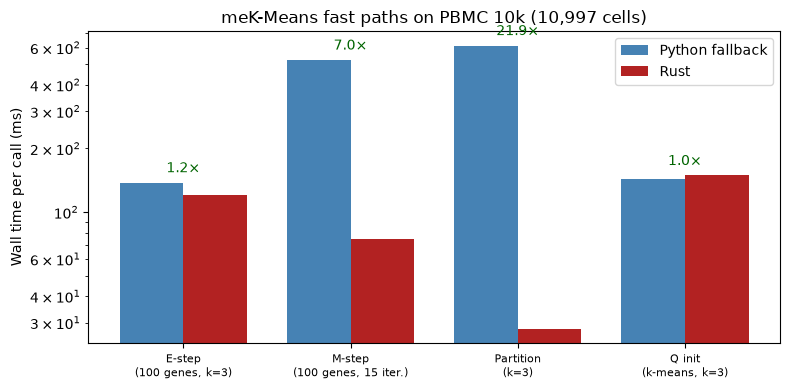

In [16]:
rows = [('E-step',    f'{N_GENES} genes, k={K}',                     py_e_times[-1], rust_e_times[-1]),
        ('M-step',    f'{N_GENES} genes, {GRAD["max_iterations"]} iter.', py_m_times[-1], rust_m_times[-1]),
        ('Partition', f'k={K}',  py_p_times[K_VALUES.index(K)], rust_p_times[K_VALUES.index(K)])]
if mm._HAS_KMEANS:
    rows.append(('Q init', f'k-means, k={K}', t_py_q, t_rust_q))

print(f'{"Step":<10} {"Setting":<24} {"Python":>10} {"Rust":>10} {"Speedup":>8}')
for name, setting, tp, tr in rows:
    print(f'{name:<10} {setting:<24} {tp:8.0f} ms {tr:8.0f} ms {tp/tr:7.1f}×')

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(rows)); w = 0.38
ax.bar(x - w/2, [r[2] for r in rows], w, color=C_PY,   label='Python fallback')
ax.bar(x + w/2, [r[3] for r in rows], w, color=C_RUST, label='Rust')
for xi, (_, _, tp, tr) in enumerate(rows):
    ax.text(xi, max(tp, tr) * 1.08, f'{tp/tr:.1f}×', ha='center', va='bottom', color='darkgreen')
ax.set_xticks(x); ax.set_xticklabels([f'{r[0]}\n({r[1]})' for r in rows], fontsize=8)
ax.set_yscale('log'); ax.set_ylabel('Wall time per call (ms)')
ax.set_title(f'meK-Means fast paths on PBMC 10k ({n_cells:,} cells)')
ax.legend()
fig.tight_layout()
plt.savefig('figures/pbmc_fastpath_breakdown.png', dpi=150)
plt.show()


---
## 5  Two-stage meK-Means with technical noise (3×4 grid)

Standard meK-Means (sections 1–4, and `mek_means.ipynb`) uses `seq_model='None'`, so technical noise
parameters η are fixed at zero — no grid search needed.

When `seq_model='Poisson'` and a non-trivial grid is requested, a **label-switching
problem** prevents running meK-Means independently at each grid point: different EM runs
can converge to incomparable cluster labelings, making it impossible to aggregate results.

The two-stage solution:

| Stage | What runs | Why |
|---|---|---|
| **1 — standard inference** | Full-population L-BFGS-B over 3×4 = 12 grid points | Finds the optimal capture rates η̂ for the batch |
| **2 — meK-Means at fixed η̂** | EM clustering at the single optimal point | No label switching; η is a batch-level property shared across clusters |

`perform_inference` does the same when `mek_means_params` is given together with a
sampling grid of more than one point.

In [17]:
# ── Model and grid setup ─────────────────────────────────────────────────────
MODEL_P  = CMEModel('Bursty', 'Poisson')
GRIDSIZE = [3, 4]                 # 12 grid points
SAMP_LB  = [-3.0, -2.5]           # narrower than the defaults, for speed
SAMP_UB  = [-1.0, -0.5]
GRAD_P   = {'max_iterations': 10, 'init_pattern': 'moments', 'num_restarts': 1}
K_EM, N_EPOCHS = K, 6

print(f'Model : {MODEL_P.bio_model} + {MODEL_P.seq_model}')
print(f'Grid  : {GRIDSIZE[0]}×{GRIDSIZE[1]} = {GRIDSIZE[0]*GRIDSIZE[1]} points')
print(f'η range: log10 α_u ∈ [{SAMP_LB[0]}, {SAMP_UB[0]}], log10 α_s ∈ [{SAMP_LB[1]}, {SAMP_UB[1]}]')
print(f'Reusing search_data ({search_data.n_genes} genes, {n_cells:,} cells): '
      'the histograms do not depend on the model.')


Model : Bursty + Poisson
Grid  : 3×4 = 12 points
η range: log10 α_u ∈ [-3.0, -1.0], log10 α_s ∈ [-2.5, -0.5]
Reusing search_data (100 genes, 10,997 cells): the histograms do not depend on the model.


### Stage 1 — standard inference over the 3×4 η grid

`InferenceParameters.fit_all_grid_points` runs L-BFGS-B for all genes at each of the
12 grid points, then `find_sampling_optimum` selects the point with the lowest total KLD.

> Runtime: a few seconds with the Rust optimizer (12 grid points × 100 genes × 10 L-BFGS-B iterations).

In [18]:
# ── Stage 1: standard inference over 3×4 η grid ─────────────────────────────
ip_stage1 = InferenceParameters(
    'pbmc_mek_means_rust', MODEL_P,
    use_lengths=False,
    gradient_params=GRAD_P,
    samp_lb=SAMP_LB, samp_ub=SAMP_UB, gridsize=GRIDSIZE,
)
print(f'Stage 1: {ip_stage1.n_grid_points} grid points')
print('Grid values (α_u, α_s):')
for pt in ip_stage1.sampl_vals:
    print(f'  ({pt[0]:.3f}, {pt[1]:.3f})')

t0 = time.perf_counter()
sr1 = ip_stage1.fit_all_grid_points(search_data)
t_stage1 = time.perf_counter() - t0
print(f'\nStage 1 complete in {t_stage1:.1f}s')

sr1.find_sampling_optimum(discard_rejected=False)
eta_opt = list(sr1.samp_optimum)
print(f'\nOptimal η (log10 capture rates): {[f"{v:.3f}" for v in eta_opt]}')
print(f'  α_u ≈ {10**eta_opt[0]:.4f}  (unspliced capture rate)')
print(f'  α_s ≈ {10**eta_opt[1]:.4f}  (spliced capture rate)')

Stage 1: 12 grid points
Grid values (α_u, α_s):
  (-3.000, -2.500)
  (-3.000, -1.833)
  (-3.000, -1.167)
  (-3.000, -0.500)
  (-2.000, -2.500)
  (-2.000, -1.833)
  (-2.000, -1.167)
  (-2.000, -0.500)
  (-1.000, -2.500)
  (-1.000, -1.833)
  (-1.000, -1.167)
  (-1.000, -0.500)


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:  17%|█▋        | 2/12 [00:00<00:00, 15.04it/s]

Grid scan:  33%|███▎      | 4/12 [00:00<00:00, 15.99it/s]

Grid scan:  50%|█████     | 6/12 [00:00<00:00, 15.00it/s]

Grid scan:  67%|██████▋   | 8/12 [00:00<00:00, 16.05it/s]

Grid scan:  83%|████████▎ | 10/12 [00:00<00:00, 15.73it/s]

Grid scan: 100%|██████████| 12/12 [00:00<00:00, 14.03it/s]

Grid scan: 100%|██████████| 12/12 [00:00<00:00, 14.78it/s]


Stage 1 complete in 0.8s

Optimal η (log10 capture rates): ['-1.000', '-1.167']
  α_u ≈ 0.1000  (unspliced capture rate)
  α_s ≈ 0.0681  (spliced capture rate)


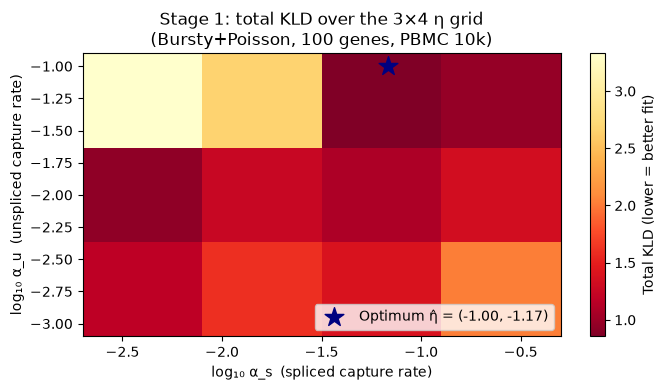

Optimal grid point index: 10


In [19]:
# ── KLD landscape over the 3×4 grid ──────────────────────────────────────────
# sr1.obj_func: array of shape (n_grid_points,) — total KLD at each grid point.
kld_vals = sr1.obj_func   # already a numpy array after clean_up inside aggregate

# Build grid arrays for plotting
u_vals = np.linspace(SAMP_LB[0], SAMP_UB[0], GRIDSIZE[0])
s_vals = np.linspace(SAMP_LB[1], SAMP_UB[1], GRIDSIZE[1])
kld_grid = kld_vals.reshape(GRIDSIZE[0], GRIDSIZE[1])

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(kld_grid, aspect='auto', origin='lower',
               extent=[s_vals[0] - 0.2, s_vals[-1] + 0.2,
                       u_vals[0] - 0.1, u_vals[-1] + 0.1],
               cmap='YlOrRd_r')
plt.colorbar(im, ax=ax, label='Total KLD (lower = better fit)')

# Mark optimum
opt_u, opt_s = eta_opt
ax.scatter([opt_s], [opt_u], marker='*', s=200, c='navy', zorder=5,
           label=f'Optimum η̂ = ({opt_u:.2f}, {opt_s:.2f})')

ax.set_xlabel('log₁₀ α_s  (spliced capture rate)')
ax.set_ylabel('log₁₀ α_u  (unspliced capture rate)')
ax.set_title(f'Stage 1: total KLD over the 3×4 η grid\n(Bursty+Poisson, {N_GENES} genes, PBMC 10k)')
ax.legend(loc='lower right')
fig.tight_layout()
plt.savefig('figures/pbmc_stage1_kld_landscape.png', dpi=150)
plt.show()
print(f'Optimal grid point index: {sr1.samp_optimum_ind}')

### Stage 2 — meK-Means at fixed η̂

`MEKMeansParameters` is constructed with `samp_lb = samp_ub = η̂` and `gridsize=[1,1]`,
so there is exactly one grid point. `run_mek_means` runs the full EM and returns a list of
`SearchResults` objects — one per cluster.

> Runtime: a few seconds (k=3 clusters, 6 epochs, 100 genes).

In [20]:
# ── Stage 2: meK-Means at fixed η̂ ────────────────────────────────────────────
mekm = MEKMeansParameters(
    'pbmc_mek_means_rust', MODEL_P,
    use_lengths=False,
    gradient_params=GRAD_P,
    samp_lb=eta_opt,       # fix both bounds to the Stage 1 optimum
    samp_ub=eta_opt,
    gridsize=[1, 1],       # single point → no label-switching risk
    k=K_EM, epochs=N_EPOCHS, random_state=0,
)
print(f'Stage 2: n_grid_points = {mekm.n_grid_points}  '
      f'(η fixed at {[f"{v:.3f}" for v in eta_opt]})')

t0 = time.perf_counter()
sr2_list = mekm.run_mek_means(search_data)
t_stage2 = time.perf_counter() - t0
print(f'Stage 2 complete in {t_stage2:.1f}s')
print(f'Clusters returned: {len(sr2_list)}')

Stage 2: n_grid_points = 1  (η fixed at ['-1.000', '-1.167'])


Stage 2 complete in 2.1s
Clusters returned: 3


In [21]:
# ── Matched baseline: Bursty+None at the same settings ───────────────────────
# Same gradient settings, k, epochs and seed as stage 2, without technical noise.
mekm_base = MEKMeansParameters('pbmc_mek_means_rust', MODEL, use_lengths=False,
                               gradient_params=GRAD_P, k=K_EM, epochs=N_EPOCHS, random_state=0)
t0 = time.perf_counter()
sr_base_list = mekm_base.run_mek_means(search_data)
t_base = time.perf_counter() - t0
print(f'Baseline complete in {t_base:.1f}s  |  {len(sr_base_list)} clusters')


Baseline complete in 1.9s  |  3 clusters


In [22]:
# ── Cluster assignments and ARI against the annotated cell types ─────────────
true_labels = adata.obs.loc[adata_ext.obs_names, 'subclass_label'].to_numpy()

assigns_2s   = cell_assignments(sr2_list, n_cells)
assigns_base = cell_assignments(sr_base_list, n_cells)
ari_2s   = adjusted_rand_score(true_labels, assigns_2s)
ari_base = adjusted_rand_score(true_labels, assigns_base)
print(f'Two-stage ARI (Bursty+Poisson, fixed η̂) = {ari_2s:.3f}')
print(f'Baseline ARI  (Bursty+None)               = {ari_base:.3f}')
print('\nCluster sizes (two-stage):')
for k in range(K_EM):
    print(f'  Cluster {k}: {(assigns_2s == k).sum():,} cells')


Two-stage ARI (Bursty+Poisson, fixed η̂) = 0.578
Baseline ARI  (Bursty+None)               = 0.570

Cluster sizes (two-stage):
  Cluster 0: 2,814 cells
  Cluster 1: 5,320 cells
  Cluster 2: 2,863 cells


Gradient settings for both: max_iterations=10, num_restarts=1

Baseline  (Bursty+None, no grid scan):
  EM only                 1939 ms

Two-stage (Bursty+Poisson, 3×4 grid):
  Stage 1 grid scan        815 ms  (12 grid points × 100 genes)
  Stage 2 meK-Means       2072 ms  (k=3, 6 epochs at fixed η̂)
  Total                   2887 ms  (1.5× the baseline)


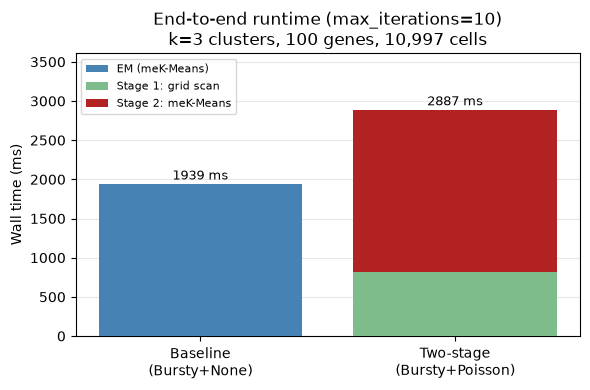

In [23]:
# ── Timing: two-stage vs the matched baseline ────────────────────────────────
t_total_2s = t_stage1 + t_stage2
print(f'Gradient settings for both: max_iterations={GRAD_P["max_iterations"]}, '
      f'num_restarts={GRAD_P["num_restarts"]}\n')
print('Baseline  (Bursty+None, no grid scan):')
print(f'  EM only              {t_base*1e3:7.0f} ms\n')
print('Two-stage (Bursty+Poisson, 3×4 grid):')
print(f'  Stage 1 grid scan    {t_stage1*1e3:7.0f} ms  ({ip_stage1.n_grid_points} grid points × {N_GENES} genes)')
print(f'  Stage 2 meK-Means    {t_stage2*1e3:7.0f} ms  (k={K_EM}, {N_EPOCHS} epochs at fixed η̂)')
print(f'  Total                {t_total_2s*1e3:7.0f} ms  ({t_total_2s/t_base:.1f}× the baseline)')

fig, ax = plt.subplots(figsize=(6, 4))
methods = ['Baseline\n(Bursty+None)', 'Two-stage\n(Bursty+Poisson)']
ax.bar(methods[0], t_base * 1e3,   color=C_PY,      label='EM (meK-Means)', zorder=3)
ax.bar(methods[1], t_stage1 * 1e3, color='#7fbc8c', label='Stage 1: grid scan', zorder=3)
ax.bar(methods[1], t_stage2 * 1e3, bottom=t_stage1 * 1e3,
       color=C_RUST, label='Stage 2: meK-Means', zorder=3)
for x, total in zip(methods, [t_base, t_total_2s]):
    ax.text(x, total * 1e3 + 20, f'{total*1e3:.0f} ms', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Wall time (ms)')
ax.set_title(f'End-to-end runtime (max_iterations={GRAD_P["max_iterations"]})\n'
             f'k={K_EM} clusters, {N_GENES} genes, {n_cells:,} cells')
ax.legend(loc='upper left', fontsize=8)
ax.set_ylim(0, max(t_base, t_total_2s) * 1e3 * 1.25)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.savefig('figures/pbmc_twostage_timing.png', dpi=150)
plt.show()


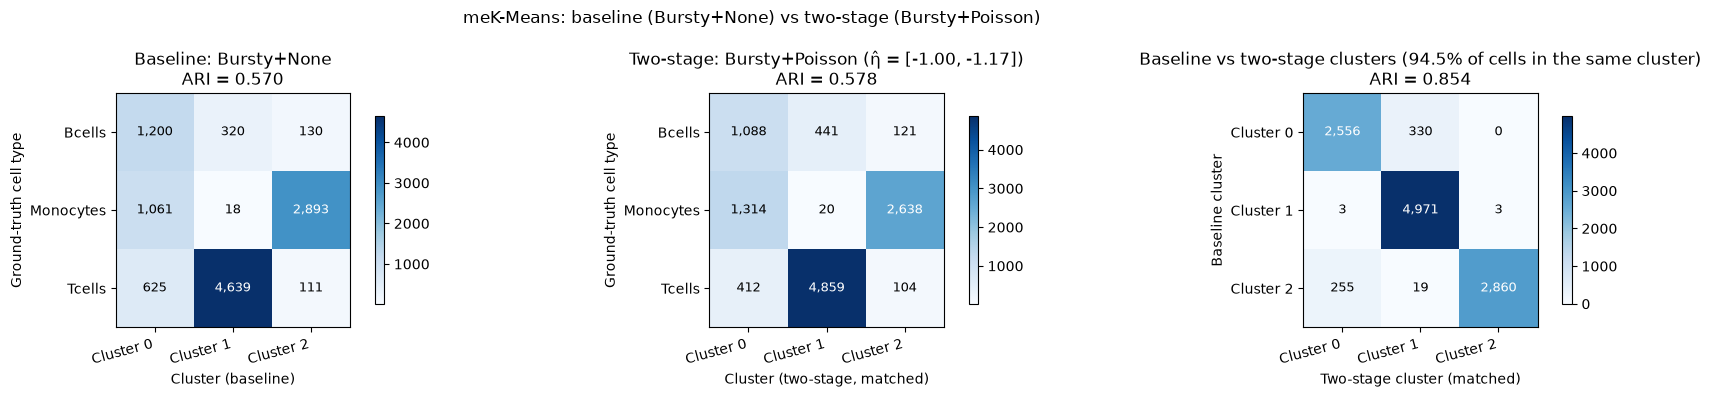

Cells placed in the same cluster by the baseline and the two-stage run: 94.5%


In [24]:
# ── Confusion matrices: against the cell types, and baseline vs two-stage ────
# Cluster indices are arbitrary: match the two-stage clusters to the baseline ones.
assigns_2s_aligned = match_clusters(assigns_base, assigns_2s)
agreement = (assigns_base == assigns_2s_aligned).mean()
cluster_labels = [f'Cluster {k}' for k in range(K_EM)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
plot_cluster_confusion(true_labels, assigns_base, ax=axes[0], align=False,
                       title='Baseline: Bursty+None')
axes[0].set_ylabel('Ground-truth cell type'); axes[0].set_xlabel('Cluster (baseline)')
plot_cluster_confusion(true_labels, assigns_2s_aligned, ax=axes[1], align=False,
                       title=f'Two-stage: Bursty+Poisson (η̂ = [{eta_opt[0]:.2f}, {eta_opt[1]:.2f}])')
axes[1].set_ylabel('Ground-truth cell type'); axes[1].set_xlabel('Cluster (two-stage, matched)')
plot_cluster_confusion(assigns_base, assigns_2s_aligned, ax=axes[2], align=False, row_names=cluster_labels,
                       title=f'Baseline vs two-stage clusters ({agreement:.1%} of cells in the same cluster)')
axes[2].set_ylabel('Baseline cluster'); axes[2].set_xlabel('Two-stage cluster (matched)')
fig.suptitle('meK-Means: baseline (Bursty+None) vs two-stage (Bursty+Poisson)', fontsize=12)
fig.tight_layout()
plt.savefig('figures/pbmc_twostage_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Cells placed in the same cluster by the baseline and the two-stage run: {agreement:.1%}')